# 04 · Machine Learning (avance preliminar): clasificación sano vs. cojo por zancada
Fase CRISP-DM: *Modelado* y *Evaluación*. Entrada: `data/processed/imu_zancadas_limpio.csv` (notebook 03).

**Pregunta predictiva:** dadas las métricas de simetría de una zancada de trote, ¿está el caballo cojo?

**Decisión metodológica clave: validación agrupada por caballo.** Las zancadas de un mismo caballo se parecen mucho
entre sí. Si se mezclaran en entrenamiento y prueba, el modelo "reconocería al caballo" y la métrica saldría inflada.
En un caso real el sistema evaluará **caballos que nunca vio**, así que:
- *Hold-out*: 5 caballos completos (≈ 23 %) se reservan como **prueba final**.
- Selección de modelo e hiperparámetros: **GroupKFold (5)** dentro de los 17 caballos de entrenamiento.
- Robustez: **Leave-One-Horse-Out** sobre los 22 caballos para el modelo final.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (RocCurveDisplay, balanced_accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, GroupKFold, GroupShuffleSplit, LeaveOneGroupOut,
                                     RandomizedSearchCV, cross_validate)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from scipy.stats import loguniform

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "docs" / "figures"; OUT = ROOT / "data" / "processed"; MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
SEED = 42

df = pd.read_csv(OUT / "imu_zancadas_limpio.csv")
FEATS = [c for c in df.columns if c.endswith(("_mm", "_hr", "_rms")) or c == "duracion_zancada_s"]
X, y, g = df[FEATS], df["cojo"], df["id_caballo"]
print(f"Zancadas: {len(df)} | variables: {len(FEATS)} | caballos: {g.nunique()} | % cojo: {y.mean()*100:.1f}")

Zancadas: 1817 | variables: 27 | caballos: 22 | % cojo: 52.2


## 1. Partición train/test por caballo (estratificada por experimento)

In [2]:
gss = GroupShuffleSplit(n_splits=200, test_size=5, random_state=SEED)
for tr, te in gss.split(X, y, g):
    exp_te = df.iloc[te].groupby("experimento")["id_caballo"].nunique()
    if len(exp_te) == 2 and exp_te.min() >= 2 and 0.4 < y.iloc[te].mean() < 0.6:
        break  # prueba con caballos de ambos experimentos y clases balanceadas
X_tr, X_te, y_tr, y_te, g_tr, g_te = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te], g.iloc[tr], g.iloc[te]
print("Caballos de prueba:", sorted(g_te.unique()))
print(f"Train: {len(X_tr)} zancadas ({g_tr.nunique()} caballos) | Test: {len(X_te)} zancadas ({g_te.nunique()} caballos)")
cv = GroupKFold(n_splits=5)

Caballos de prueba: ['ant_A', 'ant_B', 'ant_I', 'pos_D', 'pos_F']
Train: 1473 zancadas (17 caballos) | Test: 344 zancadas (5 caballos)


## 2. Modelos base y ensembles con el mismo pipeline
`SimpleImputer(mediana) → StandardScaler → modelo`. El escalado se ajusta solo con los datos de entrenamiento de
cada fold, así que no hay fuga de información. Métrica principal: **ROC-AUC** (no depende del umbral y es estable
con clases casi balanceadas). También se reportan F1 y exactitud balanceada.

In [3]:
def pipe(model):
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("clf", model)])

modelos = {
    "Regresión logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}
scoring = {"roc_auc": "roc_auc", "f1": "f1", "bal_acc": "balanced_accuracy"}
filas = []
for nombre, m in modelos.items():
    t0 = time.time()
    r = cross_validate(pipe(m), X_tr, y_tr, groups=g_tr, cv=cv, scoring=scoring, n_jobs=-1)
    filas.append({"modelo": nombre, **{f"{k}_media": r[f"test_{k}"].mean() for k in scoring},
                  "roc_auc_std": r["test_roc_auc"].std(), "tiempo_s": time.time() - t0})
base = pd.DataFrame(filas).sort_values("roc_auc_media", ascending=False)
base.round(3)

,modelo,roc_auc_media,f1_media,bal_acc_media,roc_auc_std,tiempo_s
0,Regresión logística,0.665,0.595,0.607,0.109,1.267
2,SVM (RBF),0.665,0.593,0.622,0.105,0.504
1,KNN (k=15),0.661,0.601,0.623,0.109,0.108
3,Random Forest,0.646,0.539,0.593,0.081,3.194
5,Gradient Boosting,0.611,0.536,0.567,0.095,2.103
4,AdaBoost,0.603,0.554,0.576,0.097,2.447


## 3. Optimización de hiperparámetros
- **Grid Search** para Random Forest y Gradient Boosting (espacios pequeños y discretos).
- **Random Search** para SVM (C y gamma son continuos en escala logarítmica, donde una búsqueda aleatoria es más
  eficiente que una grilla).
Siempre con GroupKFold por caballo.

In [4]:
busquedas = {
    "Random Forest": GridSearchCV(pipe(RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1)), {
        "clf__n_estimators": [200, 500], "clf__max_depth": [4, 8, None],
        "clf__min_samples_leaf": [1, 5, 20], "clf__max_features": ["sqrt", 0.5]},
        scoring="roc_auc", cv=cv, n_jobs=-1),
    "Gradient Boosting": GridSearchCV(pipe(GradientBoostingClassifier(random_state=SEED)), {
        "clf__n_estimators": [100, 300], "clf__learning_rate": [0.03, 0.1], "clf__max_depth": [2, 3],
        "clf__subsample": [0.7, 1.0]},
        scoring="roc_auc", cv=cv, n_jobs=-1),
    "SVM (RBF)": RandomizedSearchCV(pipe(SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=SEED)), {
        "clf__C": loguniform(1e-2, 1e2), "clf__gamma": loguniform(1e-4, 1e0)},
        n_iter=30, scoring="roc_auc", cv=cv, n_jobs=-1, random_state=SEED),
}
opt = []
for nombre, s in busquedas.items():
    t0 = time.time(); s.fit(X_tr, y_tr, groups=g_tr)
    opt.append({"modelo": nombre, "roc_auc_cv": s.best_score_, "mejores_parametros": s.best_params_, "tiempo_s": time.time() - t0})
opt = pd.DataFrame(opt).sort_values("roc_auc_cv", ascending=False)
pd.set_option("display.max_colwidth", 200)
opt.round(3)

,modelo,roc_auc_cv,mejores_parametros,tiempo_s
2,SVM (RBF),0.677,"{'clf__C': 5.456725485601478, 'clf__gamma': 0.005762487216478602}",17.412
0,Random Forest,0.666,"{'clf__max_depth': 8, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}",129.059
1,Gradient Boosting,0.634,"{'clf__learning_rate': 0.03, 'clf__max_depth': 3, 'clf__n_estimators': 100, 'clf__subsample': 0.7}",38.080


## 4. Evaluación final en los 5 caballos de prueba (nunca vistos)

In [5]:
res_test, probas = [], {}
for nombre, s in busquedas.items():
    p = s.best_estimator_.predict_proba(X_te)[:, 1]; probas[nombre] = p
    pred = (p >= .5).astype(int)
    res_test.append({"modelo": nombre, "roc_auc": roc_auc_score(y_te, p), "f1": f1_score(y_te, pred),
                     "bal_acc": balanced_accuracy_score(y_te, pred)})
lr = pipe(modelos["Regresión logística"]).fit(X_tr, y_tr); p = lr.predict_proba(X_te)[:, 1]; probas["Regresión logística"] = p
res_test.append({"modelo": "Regresión logística (base)", "roc_auc": roc_auc_score(y_te, p),
                 "f1": f1_score(y_te, p >= .5), "bal_acc": balanced_accuracy_score(y_te, p >= .5)})
res_test = pd.DataFrame(res_test).sort_values("roc_auc", ascending=False)
res_test.round(3)

,modelo,roc_auc,f1,bal_acc
1,Gradient Boosting,0.721,0.629,0.624
0,Random Forest,0.710,0.592,0.626
2,SVM (RBF),0.690,0.588,0.612
3,Regresión logística (base),0.684,0.627,0.625


Modelo final seleccionado por CV: Random Forest


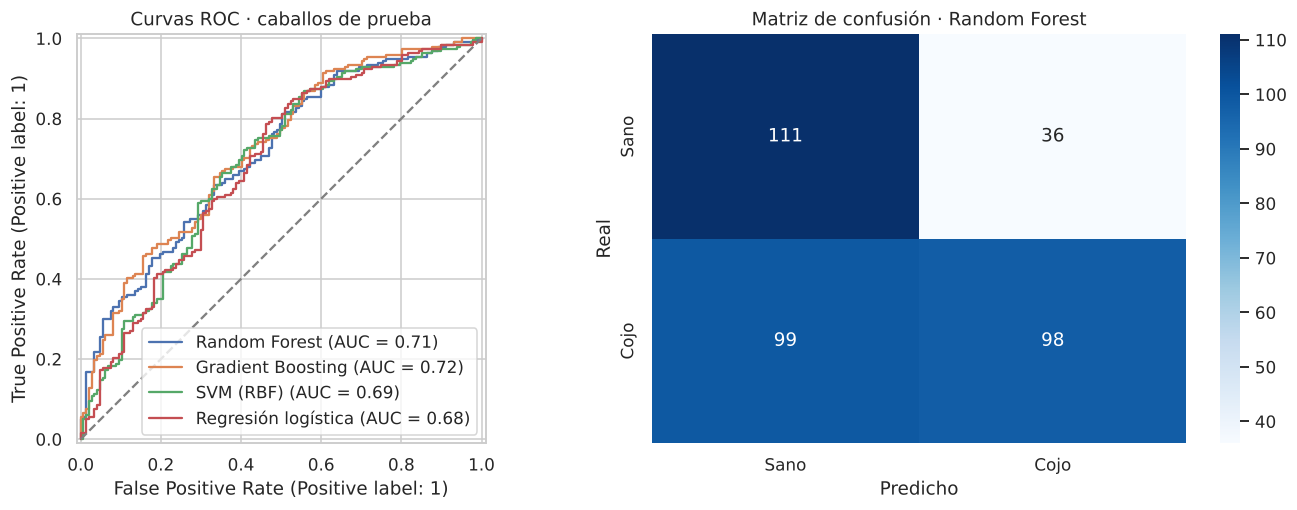

              precision    recall  f1-score   support

        Sano       0.53      0.76      0.62       147
        Cojo       0.73      0.50      0.59       197

    accuracy                           0.61       344
   macro avg       0.63      0.63      0.61       344
weighted avg       0.64      0.61      0.60       344



In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for nombre, p in probas.items():
    RocCurveDisplay.from_predictions(y_te, p, name=nombre, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "--", c="gray"); axes[0].set_title("Curvas ROC · caballos de prueba")
# Modelo final: el mejor ENSEMBLE según la validación cruzada (requisito R3). La SVM queda muy cerca en CV
# (diferencia menor que la desviación entre folds), pero el ensemble se puede explicar con SHAP de forma exacta (TreeSHAP).
mejor = opt[opt.modelo.isin(["Random Forest", "Gradient Boosting"])].iloc[0]["modelo"]
print("Modelo final seleccionado por CV:", mejor)
cm = confusion_matrix(y_te, (probas[mejor] >= .5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1], xticklabels=["Sano", "Cojo"], yticklabels=["Sano", "Cojo"])
axes[1].set(title=f"Matriz de confusión · {mejor}", xlabel="Predicho", ylabel="Real")
plt.tight_layout(); plt.savefig(FIG / "ml_roc_confusion.png"); plt.show()
print(classification_report(y_te, (probas[mejor] >= .5).astype(int), target_names=["Sano", "Cojo"]))

### Decisión a nivel de prueba (trial)
Clínicamente no se diagnostica una zancada sino una prueba de trote completa. Se promedia la probabilidad de todas
las zancadas de cada prueba (caballo × condición) y se clasifica la prueba.

In [7]:
te_df = df.iloc[te][["id_caballo", "experimento", "condicion", "cojo"]].copy()
te_df["p_cojo"] = probas[mejor]
trial = te_df.groupby(["id_caballo", "experimento", "condicion"]).agg(real=("cojo", "first"), p_media=("p_cojo", "mean"),
                                                                        n_zancadas=("p_cojo", "size")).reset_index()
trial["pred"] = (trial["p_media"] >= .5).astype(int)
trial["acierto"] = trial["pred"] == trial["real"]
print(f"Exactitud por prueba: {trial.acierto.mean()*100:.0f} % ({trial.acierto.sum()}/{len(trial)})")
trial.round(3)

Exactitud por prueba: 78 % (7/9)


,id_caballo,experimento,condicion,real,p_media,n_zancadas,pred,acierto
0,ant_A,anterior,BAS,0,0.422,34,0,True
1,ant_A,anterior,IND,1,0.501,36,1,True
2,ant_B,anterior,BAS,0,0.376,44,0,True
3,ant_B,anterior,IND,1,0.461,46,0,False
4,ant_I,anterior,BAS,0,0.318,34,0,True
5,ant_I,anterior,IND,1,0.396,35,0,False
6,pos_D,posterior,IND,1,0.546,44,1,True
7,pos_F,posterior,BAS,0,0.428,35,0,True
8,pos_F,posterior,IND,1,0.586,36,1,True


## 5. Robustez: Leave-One-Horse-Out (22 caballos)

LOHO · ROC-AUC global (out-of-fold): 0.709 | exactitud balanceada media: 0.621


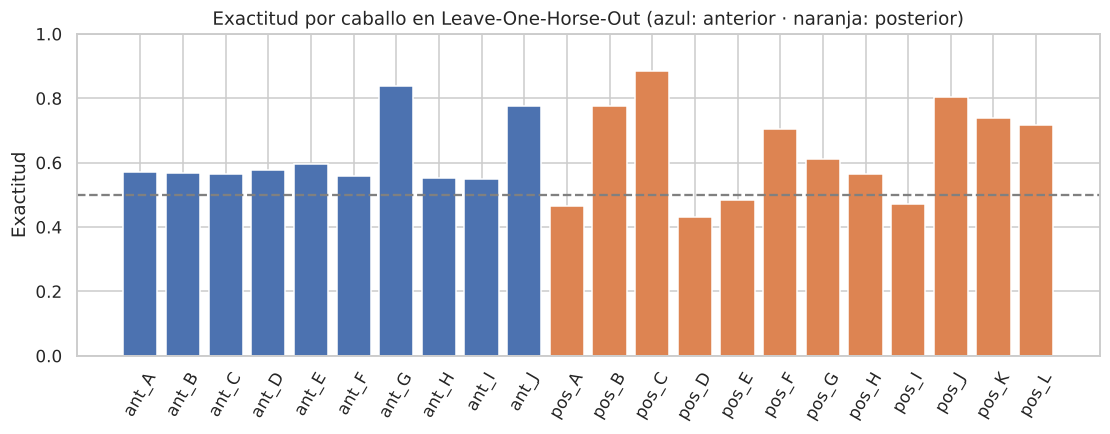

acc_zancada  p_media_sano  p_media_cojo
experimento id_caballo                                         
anterior    ant_A              0.57          0.44          0.50
            ant_B              0.57          0.46          0.52
            ant_C              0.57          0.37          0.45
            ant_D              0.58          0.46           NaN
            ant_E              0.59          0.42          0.46
            ant_F              0.56          0.53          0.57
            ant_G              0.84          0.40          0.60
            ant_H              0.55          0.46          0.56
            ant_I              0.55          0.32          0.40
            ant_J              0.78          0.47          0.62
posterior   pos_A              0.47          0.50          0.49
            pos_B              0.78          0.48          0.58
            pos_C              0.89          0.33          0.61
            pos_D              0.43           NaN          0.47
            pos_E              0.48          0.40          0.43
            pos_F              0.70          0.46          0.61
            pos_G              0.61          0.26          0.43
            pos_H              0.57          0.38          0.32
            pos_I              0.47          0.56          0.54
            pos_J              0.80          0.46          0.60
            pos_K              0.74          0.31          0.49
            pos_L              0.72          0.36          0.51

In [8]:
final = clone(busquedas[mejor].best_estimator_)
logo = LeaveOneGroupOut()
r = cross_validate(final, X, y, groups=g, cv=logo, scoring={"bal_acc": "balanced_accuracy"}, n_jobs=-1, return_estimator=False)
# AUC por caballo no está definida (una sola clase si falta una condición); se calcula AUC global con predicciones fuera de fold
from sklearn.model_selection import cross_val_predict
p_oof = cross_val_predict(final, X, y, groups=g, cv=logo, method="predict_proba", n_jobs=-1)[:, 1]
df["p_oof"] = p_oof
print(f"LOHO · ROC-AUC global (out-of-fold): {roc_auc_score(y, p_oof):.3f} | exactitud balanceada media: {r['test_bal_acc'].mean():.3f}")
por_caballo = df.groupby(["experimento", "id_caballo"]).apply(
    lambda d: pd.Series({"acc_zancada": ((d.p_oof >= .5) == d.cojo).mean(),
                         "p_media_sano": d.loc[d.cojo == 0, "p_oof"].mean(), "p_media_cojo": d.loc[d.cojo == 1, "p_oof"].mean()}))
fig, ax = plt.subplots(figsize=(12, 3.8))
pc = por_caballo.reset_index()
ax.bar(pc["id_caballo"], pc["acc_zancada"], color=np.where(pc.experimento == "anterior", "#4C72B0", "#DD8452"))
ax.axhline(.5, ls="--", c="gray"); ax.set_ylim(0, 1)
ax.set(title="Exactitud por caballo en Leave-One-Horse-Out (azul: anterior · naranja: posterior)", ylabel="Exactitud")
plt.xticks(rotation=60); plt.savefig(FIG / "ml_loho_caballos.png"); plt.show()
por_caballo.round(2)

## 6. Interpretabilidad (SHAP + importancia por permutación)

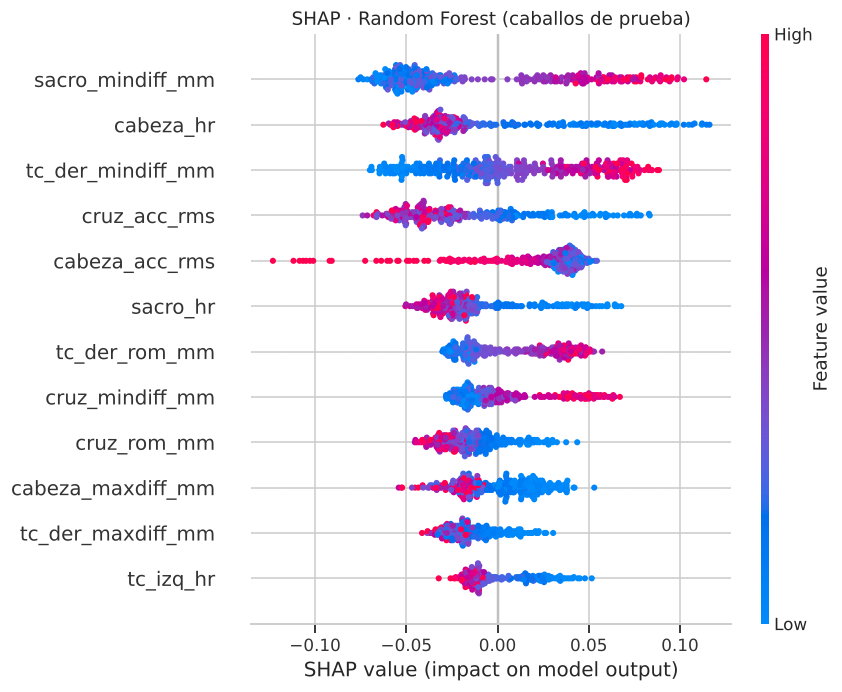

In [9]:
est = busquedas[mejor].best_estimator_
nombre_int = mejor
Xte_t = pd.DataFrame(est[:-1].transform(X_te), columns=FEATS)
explainer = shap.TreeExplainer(est.named_steps["clf"])
sv = explainer.shap_values(Xte_t)
sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if sv.ndim == 3 else sv)
plt.figure()
shap.summary_plot(sv, Xte_t, max_display=12, show=False)
plt.title(f"SHAP · {nombre_int} (caballos de prueba)")
plt.savefig(FIG / "ml_shap_summary.png"); plt.show()

In [10]:
pi = permutation_importance(est, X_te, y_te, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"variable": FEATS, "perm_importancia": pi.importances_mean, "perm_std": pi.importances_std,
                    "shap_abs_medio": np.abs(sv).mean(axis=0)}).sort_values("shap_abs_medio", ascending=False)
imp.head(12).round(4)

,variable,perm_importancia,perm_std,shap_abs_medio
11,sacro_mindiff_mm,-0.0090,0.0117,0.0488
4,cabeza_hr,0.0579,0.0091,0.0395
21,tc_der_mindiff_mm,0.0046,0.0115,0.0354
10,cruz_acc_rms,0.0234,0.0106,0.0338
5,cabeza_acc_rms,0.0241,0.0064,0.0337
14,sacro_hr,0.0020,0.0053,0.0257
22,tc_der_rom_mm,0.0076,0.0063,0.0237
6,cruz_mindiff_mm,-0.0004,0.0047,0.0189
7,cruz_rom_mm,0.0050,0.0027,0.0186
3,cabeza_maxdiff_mm,0.0153,0.0039,0.0180


**Lectura:** las variables que más pesan en el modelo son las mismas que la biomecánica señala como marcadores de
cojera: la asimetría vertical de la cabeza (MinDiff y harmonic ratio) para la cojera anterior y la del sacro / tuberosidades
coxales para la posterior. Que el modelo "piense" como un veterinario da confianza para pasar a la fase de visión por
computador, donde estas mismas señales se estimarán desde video con keypoints de cabeza, cruz y pelvis.

In [11]:
import joblib, json
joblib.dump(busquedas[mejor].best_estimator_, MODELS / "modelo_cojera.joblib")
json.dump({"modelo": mejor, "features": FEATS, "caballos_test": sorted(g_te.unique().tolist()),
           "roc_auc_test": float(res_test.loc[res_test.modelo == mejor, "roc_auc"].iloc[0]),
           "roc_auc_loho": float(roc_auc_score(y, p_oof))}, open(MODELS / "modelo_cojera_meta.json", "w"), indent=2)
base.to_csv(OUT / "ml_resultados_cv.csv", index=False); res_test.to_csv(OUT / "ml_resultados_test.csv", index=False)
print("Modelo guardado en models/modelo_cojera.joblib")

Modelo guardado en models/modelo_cojera.joblib


## 7. Conclusiones del avance de ML y siguientes pasos
- Con variables de **una sola zancada** y validación con **caballos no vistos**, el modelo detecta la cojera inducida
  mejor que el azar (ROC-AUC ≈ 0,71 tanto en los 5 caballos de prueba como en Leave-One-Horse-Out; 7 de 9 pruebas de trote bien clasificadas al promediar sus zancadas). Es un rendimiento **moderado**, y es
  honesto: la cojera inducida es leve y algunos caballos son asimétricos incluso sanos.
- La validación agrupada es la decisión más importante del avance: con una partición aleatoria por zancada las métricas
  saldrían infladas, porque el modelo reconocería a cada caballo.
- **Para la entrega final:** (1) normalizar cada caballo frente a una sesión de referencia propia (seguimiento
  longitudinal), (2) usar asimetrías con signo, identificando el miembro con los sensores de casco, (3) agregar
  modelos de regresión para estimar el grado de asimetría, y (4) servir el modelo como API en AWS.